In [1]:
from datetime import timedelta

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

file = "'../data/process_data.json'"

exploded_events = duckdb.sql(f"""
        WITH unnested AS(
        SELECT Time as processing_time,
        unnest(ProcessData::JSON[]) as event
        FROM {file}
        )

        SELECT processing_time,
        event->>'$.Name' as name,
        event->>'$.Value' as value,
        event->>'$.Type' as type,
        event->>'$.Time' as event_time,
        event->>'$.Unit' as unit,
        FROM unnested
        """)

pivoted_events = duckdb.sql("""
        WITH pivoted AS(
        PIVOT exploded_events
        ON name
        USING FIRST(value)
        GROUP BY processing_time
        ORDER BY processing_time
        )
        SELECT CAST(processing_time AS TIMESTAMP_MS) as time,
        CAST("fAnlasstemperatur (Anlassen)" AS DOUBLE) as anlasstemp,
        CAST("fDrahtlaenge1 (Drehgeber)" AS DOUBLE) as drahtlaenge,
        CAST("fDurchmesser1 (Haerten)" AS DOUBLE) as durchmesser,
        CAST("fGeschwindigkeit1 (Drehgeber)" AS DOUBLE) as geschwindigkeit,
        CAST("fHaertetemperatur (Haerten)" AS DOUBLE) as haertetemp 
        FROM pivoted
        """)

In [2]:
df = duckdb.sql("""
        SELECT time, geschwindigkeit, haertetemp as h_temp, anlasstemp as a_temp
        FROM pivoted_events
""").df()

In [3]:
duckdb.sql("""
        SELECT min(time), max(time)
        FROM pivoted_events
""").df()

,"min(""time"")","max(""time"")"
0,2026-01-01 06:00:00,2026-01-01 06:59:59.900


In [4]:
# Temperatur um `lag` Messwerte nach vorn verschoben: Wirkt die Geschwindigkeit verzögert?
lags = range(0, 1000)
correlations = []

for lag in lags:
    corr = df["geschwindigkeit"].corr(df["h_temp"].shift(-lag), method="pearson")
    correlations.append(corr)

lags_df = pd.DataFrame({"lag": lags, "correlation": correlations})

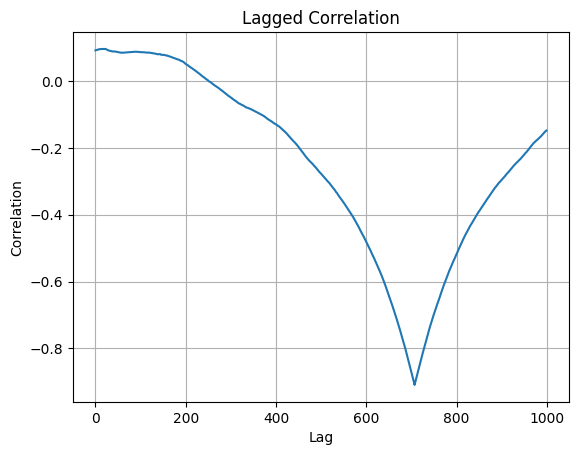

In [5]:
plt.plot(lags_df["lag"], lags_df["correlation"])
plt.xlabel("Lag")
plt.ylabel("Correlation")
plt.title("Lagged Correlation")
plt.grid()
plt.show()

In [6]:
lags_df[lags_df.correlation == lags_df.correlation.min()]

,lag,correlation
707,707,-0.90935


In [7]:
def compute_lagged_speed(df, lag_seconds=70.7):
    """
    Führt einen zeitbasierten Left Join durch:
    Für jede Zeile (Temperatur) wird die Geschwindigkeit von 'lag_seconds' Sekunden früher geholt.
    """
    df_temp = df[["time", "h_temp"]].copy()
    df_speed = df[["time", "geschwindigkeit"]].copy()

    # Join-Zeitpunkt für die Geschwindigkeit
    df_speed["join_time"] = df_speed["time"] + pd.Timedelta(seconds=lag_seconds)

    # Exakter Merge (left join) auf die Zeitstempel
    df_joined = pd.merge(
        df_temp, df_speed, left_on="time", right_on="join_time", how="left", suffixes=("", "_lag")
    )

    # Umbenennen und Aufräumen
    df_joined = df_joined.rename(columns={"geschwindigkeit": "geschwindigkeit_delayed"})
    df_joined = df_joined.drop(columns=["join_time", "time_lag"])
    return df_joined[["time", "h_temp", "geschwindigkeit_delayed"]]


def calculate_window_corr_join(df, window_minutes=2, slide_seconds=10, lag_seconds=70.7):
    # Zeitbasis festlegen (z.B. erster Zeitstempel im DataFrame)
    start_time = df["time"].min()
    end_time = start_time + timedelta(hours=1)

    # Zeitversetzte Geschwindigkeit hinzufügen
    df_lagged = compute_lagged_speed(df, lag_seconds)

    window_sec = window_minutes * 60
    results = []

    current_start = start_time
    while current_start + timedelta(seconds=window_sec) <= end_time:
        window_end = current_start + timedelta(seconds=window_sec)

        # Fenster ausschneiden (basierend auf Original-Zeit, nicht auf join_time)
        window_df = df_lagged[
            (df_lagged["time"] >= current_start) & (df_lagged["time"] < window_end)
        ]

        # Korrelation berechnen (ignoriert NaN automatisch)
        pearson = window_df["h_temp"].corr(window_df["geschwindigkeit_delayed"])
        count_h_temp = window_df["h_temp"].count()
        count_speed = window_df["geschwindigkeit_delayed"].count()

        results.append(
            {
                "start_time": current_start,
                "end_time": window_end,
                "count_temp": count_h_temp,
                "count_speed": count_speed,
                "pearson": pearson,
            }
        )

        current_start += timedelta(seconds=slide_seconds)

    return pd.DataFrame(results)

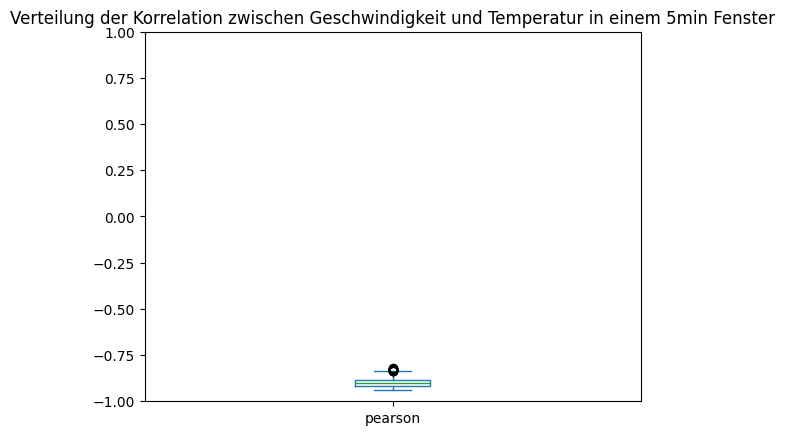

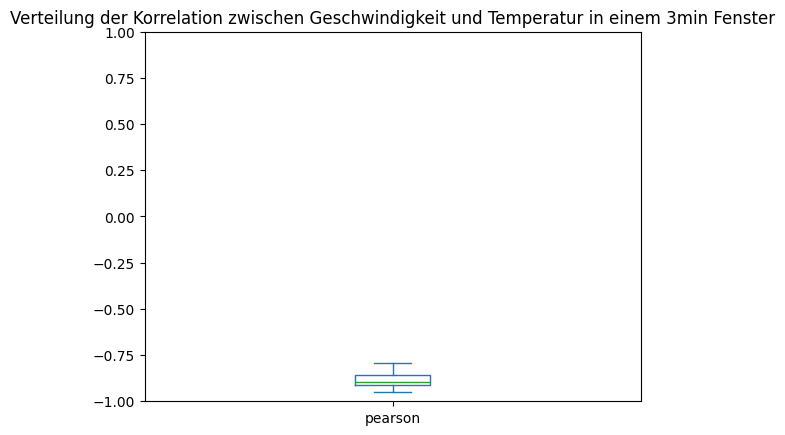

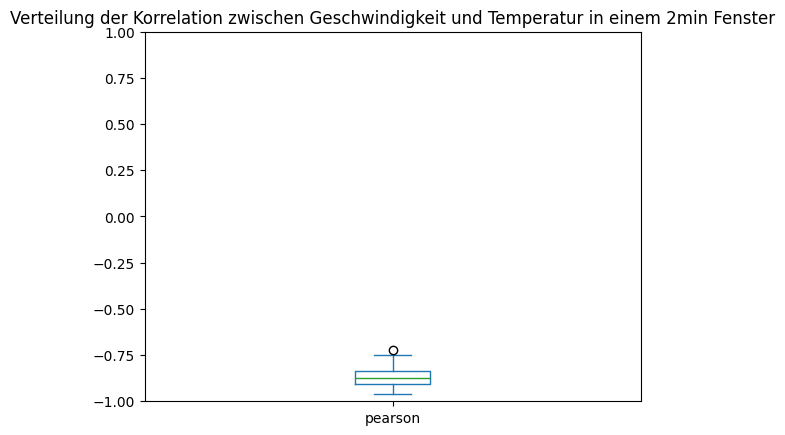

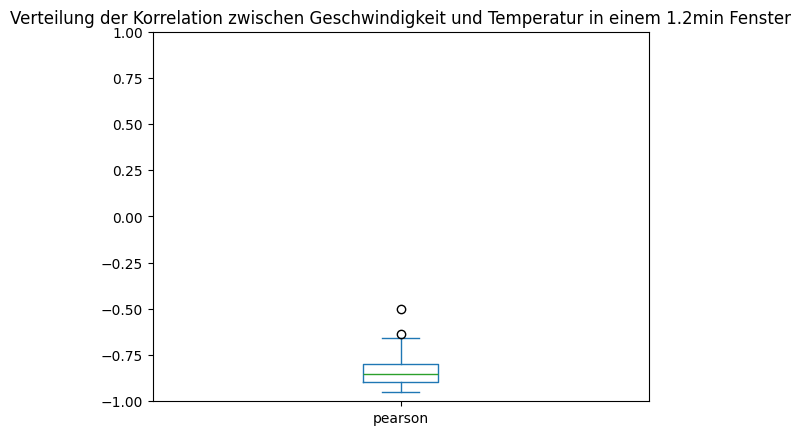

In [8]:
for window in [5, 3, 2, 1.2]:
    correlations_df = calculate_window_corr_join(
        df, window_minutes=window, slide_seconds=10, lag_seconds=70.7
    )
    correlations_df.pearson.plot(
        kind="box",
        ylim=(-1, 1),
        title=f"Verteilung der Korrelation zwischen Geschwindigkeit und Temperatur in einem {window}min Fenster",
    )
    plt.show()

**Ergebnisse**

- Die Auswirkung der Geschwindigkeit auf die Temperatur ist zeitversetzt (707 Ticks -> 70,7 Sekunden)
- Größere Fenster liefern eine stärkere und stabilere Korrelation, reagieren aber langsamer auf Änderungen. In kurzen Fenstern mit fast gleichbleibender Geschwindigkeit ist kaum ein Effekt messbar

**Vorgehen**
- Es sollte ein 2 Minuten Window implementiert werden, weil es kurzfristige Zusammenhänge erkennt und dabei ausreichend groß ist um genügend Messwerte für eine stabile statistische Aussage zu sammeln. Für die Berechnung der Korrelation wird die Geschwindigkeit um 70,7 Sekunden verzögert um die Dauer der Auswirkung auf die Temperatur zu berücksichtigen. 
- Pearson eignet sich als Korrelationsmaß da der Zusammenhang zwischen Geschwindigkeit und Temperatur in der Physik linear ist 
- Es sollte ein Sliding Window sein um ungünstige Übergänge, in denen kein Effekt zu messen ist, zu vermeiden
